<a href="https://colab.research.google.com/github/usumakikai8-bot/DNN/blob/main/dnn8_process_and_plot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DNN8 — Process test predictions and plot (grid-based)

Converts `dnn8-test-predictions.csv` into a DNN7-style dataframe and draws predicted vs. ground-truth plots.

* DNN7's member symbol (`C1`, `GX1`, ...) is replaced by the **grid position**: `slot = member:floor:X{x_line}-Y{y_line}`, e.g. `beam_X:2FL:X1-Y1`; also stored in `grid_position`.
* Nominal dimensions are looked up **by catalog ID, separately for beams and columns** (IDs overlap between the two catalogs).
* Run the cells top to bottom.

## Setup and load predictions

In [1]:
import os, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from google.colab import drive, files

drive.mount('/content/drive')

# Same paths as the dnn8 notebook (edit if yours differ)
PROJECT_ROOT = Path('/content/drive/MyDrive/research/dnn8')
os.chdir(PROJECT_ROOT)

DATASET_ROOT = PROJECT_ROOT / 'dataset'
CATALOG_ROOT = DATASET_ROOT / 'catalog'
H_CATALOG_FILE = 'beam-narrow-medium-catalog.csv'
BOX_CATALOG_FILE = 'column-all-bcr-catalog.csv'

OUTPUT_DIR = PROJECT_ROOT / 'dnn-results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
dnn = 'DNN8-grid'

PREDICTIONS_PATH = OUTPUT_DIR / 'dnn8-test-predictions.csv'
df = pd.read_csv(PREDICTIONS_PATH)
df.head()

Mounted at /content/drive


,file_name,story,member,x_line,y_line,true_id,true_name,predicted_id,predicted_name,is_correct
0,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,1,1,8,B-200x200x8x20,4,B-175x175x6x15,False
1,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_X,1,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True
2,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_Y,1,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True
3,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,column,2,1,8,B-200x200x8x20,4,B-175x175x6x15,False
4,F3_X1_4000_Y1_4000_H3500_W6p0_model.csv,1,beam_Y,2,1,7,H-250x125x6x9x8,7,H-250x125x6x9x8,True


## Catalog lookup (nominal dimensions by ID)

Check the printed "dimensions taken from" lines: the name-parsing fallback gives actual (not nominal) sizes for some H-shapes.

In [2]:
# ------------------------------------------------------------
# 1. Catalog -> nominal dimensions, looked up by ID
#    NOTE: beam IDs and column IDs overlap (both start at 1), so the
#    lookup MUST be done per catalog: beams -> H catalog, columns -> box catalog.
#    Catalogs are read in full (enabled 0/1) so that no ID is lost.
# ------------------------------------------------------------
h_cat = pd.read_csv(CATALOG_ROOT / H_CATALOG_FILE, encoding='utf-8-sig')
box_cat = pd.read_csv(CATALOG_ROOT / BOX_CATALOG_FILE, encoding='utf-8-sig')


def _first_existing(cat, candidates):
    return next((c for c in candidates if c in cat.columns), None)


def _numbers_in_name(name):
    """'H-250x125x6x9x8' -> [250, 125, 6, 9, 8],  'B-200x200x8x20' -> [200, 200, 8, 20]"""
    return [float(v) for v in re.findall(r'\d+(?:\.\d+)?', re.sub(r'^[^\-]*-', '', str(name)))]


def build_id_lookup(cat, kind):
    """id -> (dim1, dim2).   beams: (nominal H, nominal B)   columns: (D, t)"""
    if kind == 'beam':
        c1 = _first_existing(cat, ['nominal_H_mm', 'H_mm'])
        c2 = _first_existing(cat, ['nominal_B_mm', 'B_mm'])
    else:
        c1 = _first_existing(cat, ['D_mm'])
        c2 = _first_existing(cat, ['t_mm'])

    lookup = {}
    for _, r in cat.iterrows():
        if c1 and c2:
            vals = (float(r[c1]), float(r[c2]))
        else:                                   # fallback: parse the section name
            n = _numbers_in_name(r['name'])
            vals = (n[0], n[1]) if kind == 'beam' else (n[0], n[2])
        lookup[int(r['id'])] = vals
    src = f'{c1}, {c2}' if (c1 and c2) else 'section name (fallback)'
    print(f'{kind:6s} dimensions taken from: {src}')
    return lookup


H_BY_ID = build_id_lookup(h_cat, 'beam')
BOX_BY_ID = build_id_lookup(box_cat, 'column')

beam   dimensions taken from: nominal_H_mm, nominal_B_mm
column dimensions taken from: D_mm, t_mm


## Transform the dataframe (grid position, nominal dimensions)

In [3]:
# ------------------------------------------------------------
# 2. Transform the prediction dataframe
# ------------------------------------------------------------
df_transformed = df.copy()

# section type from the grid member (more reliable than parsing the name)
df_transformed['section_type'] = np.where(df_transformed['member'].eq('column'), 'box', 'h')

# grid position: X{x_line}-Y{y_line}  (replaces the DNN7 symbol CI / GX1 ...)
df_transformed['grid_position'] = (
    'X' + df_transformed['x_line'].astype(int).astype(str)
    + '-Y' + df_transformed['y_line'].astype(int).astype(str)
)

# slot = member : floor : grid position   (same role as DNN7 `slot`)
df_transformed['slot'] = (
    df_transformed['member'] + ':'
    + df_transformed['story'].astype(int).astype(str) + 'FL:'
    + df_transformed['grid_position']
)

df_transformed = df_transformed.rename(columns={
    'predicted_name': 'predicted_catalog',
    'true_name': 'true_catalog',
})


def add_dims(frame, prefix, id_col):
    """Add {prefix}_H/_B (beams) and {prefix}_D/_t (columns) from the catalog, by ID."""
    is_beam = frame['section_type'].eq('h').to_numpy()
    dims = np.array([
        H_BY_ID.get(int(i), (np.nan, np.nan)) if b else BOX_BY_ID.get(int(i), (np.nan, np.nan))
        for i, b in zip(frame[id_col], is_beam)
    ], dtype=float)
    frame[f'{prefix}_H'] = np.where(is_beam, dims[:, 0], np.nan)
    frame[f'{prefix}_B'] = np.where(is_beam, dims[:, 1], np.nan)
    frame[f'{prefix}_D'] = np.where(~is_beam, dims[:, 0], np.nan)
    frame[f'{prefix}_t'] = np.where(~is_beam, dims[:, 1], np.nan)


add_dims(df_transformed, 'pred', 'predicted_id')
add_dims(df_transformed, 'true', 'true_id')

# IDs that were not found in the catalog
for p in ('pred', 'true'):
    missing = df_transformed[df_transformed[[f'{p}_H', f'{p}_D']].isna().all(axis=1)]
    if len(missing):
        print(f'WARNING: {len(missing)} rows have a {p} ID that is not in the catalog')

# is_correct judged on the nominal class (exact sections sharing a nominal size count as equal)
df_transformed['is_correct_nominal'] = (
    df_transformed[['pred_H', 'pred_B', 'pred_D', 'pred_t']].fillna(-1)
    .eq(df_transformed[['true_H', 'true_B', 'true_D', 'true_t']].fillna(-1).to_numpy())
    .all(axis=1)
)

## Building parameters from file_name (incl. floor height), and save

In [5]:
# ------------------------------------------------------------
# 3. Building parameters recovered from file_name
#    e.g. F3_X6_9000_Y1_4000_H3500_W10p0_model.csv
# ------------------------------------------------------------
FILE_RE = re.compile(r'^F(\d+)_X(\d+)_(\d+)_Y(\d+)_(\d+)_H(\d+)_W(\d+)p(\d+)')


def parse_file_name(name):
    m = FILE_RE.match(str(name))
    if m is None:
        return (np.nan,) * 7
    f, nx, xs, ny, ys, h, w1, w2 = m.groups()
    return int(f), int(nx), int(xs), int(ny), int(ys), int(h), float(f'{w1}.{w2}')


parsed = df_transformed['file_name'].apply(parse_file_name).tolist()
df_transformed[['n_floors', 'n_x_spans', 'x_span_length', 'n_y_spans', 'y_span_length',
                'floor_height', 'load']] = (
    pd.DataFrame(parsed, index=df_transformed.index)
)

df_transformed = df_transformed[[
    'file_name', 'story', 'member', 'x_line', 'y_line', 'grid_position', 'slot', 'section_type',
    'predicted_catalog', 'true_catalog', 'predicted_id', 'true_id',
    'is_correct', 'is_correct_nominal',
    'pred_H', 'pred_B', 'pred_D', 'pred_t',
    'true_H', 'true_B', 'true_D', 'true_t',
    'n_floors', 'n_x_spans', 'x_span_length', 'n_y_spans', 'y_span_length', 'floor_height', 'load',
]]

print(df_transformed.head())
print(df_transformed.shape)

save_path = OUTPUT_DIR / f'df-transformed-{dnn}.csv'
df_transformed.to_csv(save_path, index=False, encoding='utf-8-sig')
print('Saved:', save_path)

df = df_transformed.copy()

                                 file_name  story  member  x_line  y_line  \
0  F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  column       1       1   
1  F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  beam_X       1       1   
2  F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  beam_Y       1       1   
3  F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  column       2       1   
4  F3_X1_4000_Y1_4000_H3500_W6p0_model.csv      1  beam_Y       2       1   

  grid_position              slot section_type predicted_catalog  \
0         X1-Y1  column:1FL:X1-Y1          box    B-175x175x6x15   
1         X1-Y1  beam_X:1FL:X1-Y1            h   H-250x125x6x9x8   
2         X1-Y1  beam_Y:1FL:X1-Y1            h   H-250x125x6x9x8   
3         X2-Y1  column:1FL:X2-Y1          box    B-175x175x6x15   
4         X2-Y1  beam_Y:1FL:X2-Y1            h   H-250x125x6x9x8   

      true_catalog  ...  true_B  true_D  true_t  n_floors  n_x_spans  \
0   B-200x200x8x20  ...     NaN   200.0     8.0         

## Plot function

`plot_dim_vs_variable(df, member, dim, vary, position)` — `member`: `beam_X` / `beam_Y` / `column`; `dim`: `H` (beams) or `D` (columns); `vary`: `x_span` / `load` / `story` / `floor_height`; `position`: e.g. `X1-Y1`, or `None` for automatic.

In [9]:
# ============================================================
# 4. Plot : member dimension vs. one varying building parameter
#    (generalises the four DNN7 plots)
#
#    member : 'beam_X' | 'beam_Y' | 'column'
#    dim    : 'H' (beam depth) | 'D' (column width)
#    vary   : 'x_span' | 'load' | 'story' | 'floor_height'
#    position : grid position such as 'X1-Y1'. None -> chosen automatically
#    story_fixed : floor to use when vary != 'story'. None -> chosen automatically
#
#    Everything except the varying parameter is held constant: the file name
#    (with the varying token masked) + the slot form one "building condition key".
#    The key covering the most distinct values of the varying parameter is used.
# ============================================================
VARY = {
    'x_span': dict(col='x_span_length', mask=(r'_X\d+_\d+_', '_XSPAN_'), xlabel='X-Span Length (mm)',
                   name='X_Span_Length'),
    'load':   dict(col='load', mask=(r'_W\d+p\d+_', '_WLOAD_'), xlabel='Building Load (kN/m²)',
                   name='Building_Load'),
    'floor_height': dict(col='floor_height', mask=(r'_H\d+_', '_HFLOOR_'), xlabel='Floor Height (mm)',
                         name='Floor_Height'),
    'story':  dict(col='story', mask=None, xlabel='Floor', name='Floor'),
}
DIM_LABEL = {'H': 'Member H-Length (mm)', 'D': 'Column D-Dimension (mm)'}


def plot_dim_vs_variable(df, member, dim, vary, position=None, story_fixed=None,
                         save_dir=None, show=True):
    v = VARY[vary]
    section_type = 'box' if member == 'column' else 'h'
    if (member == 'column') != (dim == 'D'):
        raise ValueError("dim must be 'D' for columns and 'H' for beams")

    d = df[(df['member'] == member) & (df['section_type'] == section_type)].copy()
    if position is not None:
        d = d[d['grid_position'] == position]
    if story_fixed is not None and vary != 'story':
        d = d[d['story'] == story_fixed]
    d = d.dropna(subset=[v['col'], f'pred_{dim}', f'true_{dim}'])

    # building-condition key (varying token masked)
    fname = d['file_name']
    if v['mask'] is not None:
        fname = fname.str.replace(v['mask'][0], v['mask'][1], regex=True)
    slot = d['slot']
    if vary == 'story':                                   # mask the floor inside the slot
        slot = slot.str.replace(r':\d+FL:', ':FL:', regex=True)
        fname = d['file_name']
    d['building_condition_key'] = fname + ' | ' + slot

    cover = d.groupby('building_condition_key')[v['col']].nunique()
    if cover.empty:
        raise ValueError('No data for the requested member / position / floor.')
    best = cover[cover == cover.max()].sort_index().index[0]      # deterministic tie-break
    summary = (d[d['building_condition_key'] == best]
               .sort_values([v['col'], 'file_name', 'slot'])
               .drop_duplicates(subset=v['col'], keep='first')
               .reset_index(drop=True))

    # ---- plot ------------------------------------------------
    fig, ax = plt.subplots(figsize=(14, 9))
    x = summary[v['col']]
    ax.plot(x, summary[f'pred_{dim}'], marker='o', linestyle='--', color='blue',
            linewidth=2, markersize=10, label='Predicted')
    ax.plot(x, summary[f'true_{dim}'], marker='x', linestyle='-', color='red',
            linewidth=2, markersize=10, label='Ground Truth')

    for i, (_, r) in enumerate(summary.iterrows(), start=1):
        ax.annotate(str(i), xy=(r[v['col']], r[f'pred_{dim}']), xytext=(7, 7),
                    textcoords='offset points', color='blue', fontsize=10, fontweight='bold')
        ax.annotate(str(i), xy=(r[v['col']], r[f'true_{dim}']), xytext=(7, -17),
                    textcoords='offset points', color='red', fontsize=10, fontweight='bold')

    handles = [
        Line2D([0], [0], color='blue', linestyle='--', marker='o', linewidth=1.5, markersize=6, label='Predicted'),
        Line2D([0], [0], color='red', linestyle='-', marker='x', linewidth=1.5, markersize=7, label='Ground Truth'),
    ]
    for i, (_, r) in enumerate(summary.iterrows(), start=1):
        handles.append(Line2D(
            [0], [0], color='none', linestyle='None', marker=None,
            label=(f'{i}. {r["file_name"]} | {r["slot"]}\n'
                   f'   Predicted {dim} = {r[f"pred_{dim}"]:g} mm   |   '
                   f'Ground Truth {dim} = {r[f"true_{dim}"]:g} mm')))
    ax.legend(handles=handles, loc='best', fontsize=8, frameon=True,
              handlelength=0, borderpad=0.8, labelspacing=0.8)

    if vary == 'story':
        ax.set_xticks(sorted(x.unique()))
    ax.set_xlabel(v['xlabel'], fontsize=12)
    ax.set_ylabel(DIM_LABEL[dim], fontsize=12)
    pos_txt = summary['grid_position'].iloc[0]
    ax.set_title(f'{DIM_LABEL[dim]} vs. {v["xlabel"]}  [{member} @ {pos_txt}]  ({dnn})', fontsize=14)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()

    save_dir = save_dir or OUTPUT_DIR
    os.makedirs(save_dir, exist_ok=True)
    out = os.path.join(save_dir, f'{dnn}-{member}-{dim}-vs-{v["name"]}-{pos_txt}.png')
    plt.savefig(out, dpi=300, bbox_inches='tight')

    print(f'Saved graph to: {out}')
    print(f'Building condition key: {best}')
    print(f'Distinct values plotted ({vary}): {summary[v["col"]].tolist()}')
    for i, (_, r) in enumerate(summary.iterrows(), start=1):
        print(f'[{i}] {r["file_name"]} | {r["slot"]} : '
              f'pred {dim}={r[f"pred_{dim}"]:g}  true {dim}={r[f"true_{dim}"]:g}')
    if show:
        plt.show()
    files.download(out)
    return summary

### Beam H vs. X-span

Saved graph to: /content/drive/MyDrive/research/dnn8/dnn-results/DNN8-grid-beam_X-H-vs-X_Span_Length-X1-Y1.png
Building condition key: F3_XSPAN_Y1_4000_H3000_W10p0_model.csv | beam_X:1FL:X1-Y1
Distinct values plotted (x_span): [4000, 5000, 6000, 7000, 8000]
[1] F3_X3_4000_Y1_4000_H3000_W10p0_model.csv | beam_X:1FL:X1-Y1 : pred H=300  true H=200
[2] F3_X1_5000_Y1_4000_H3000_W10p0_model.csv | beam_X:1FL:X1-Y1 : pred H=300  true H=300
[3] F3_X5_6000_Y1_4000_H3000_W10p0_model.csv | beam_X:1FL:X1-Y1 : pred H=350  true H=350
[4] F3_X2_7000_Y1_4000_H3000_W10p0_model.csv | beam_X:1FL:X1-Y1 : pred H=350  true H=300
[5] F3_X2_8000_Y1_4000_H3000_W10p0_model.csv | beam_X:1FL:X1-Y1 : pred H=400  true H=400


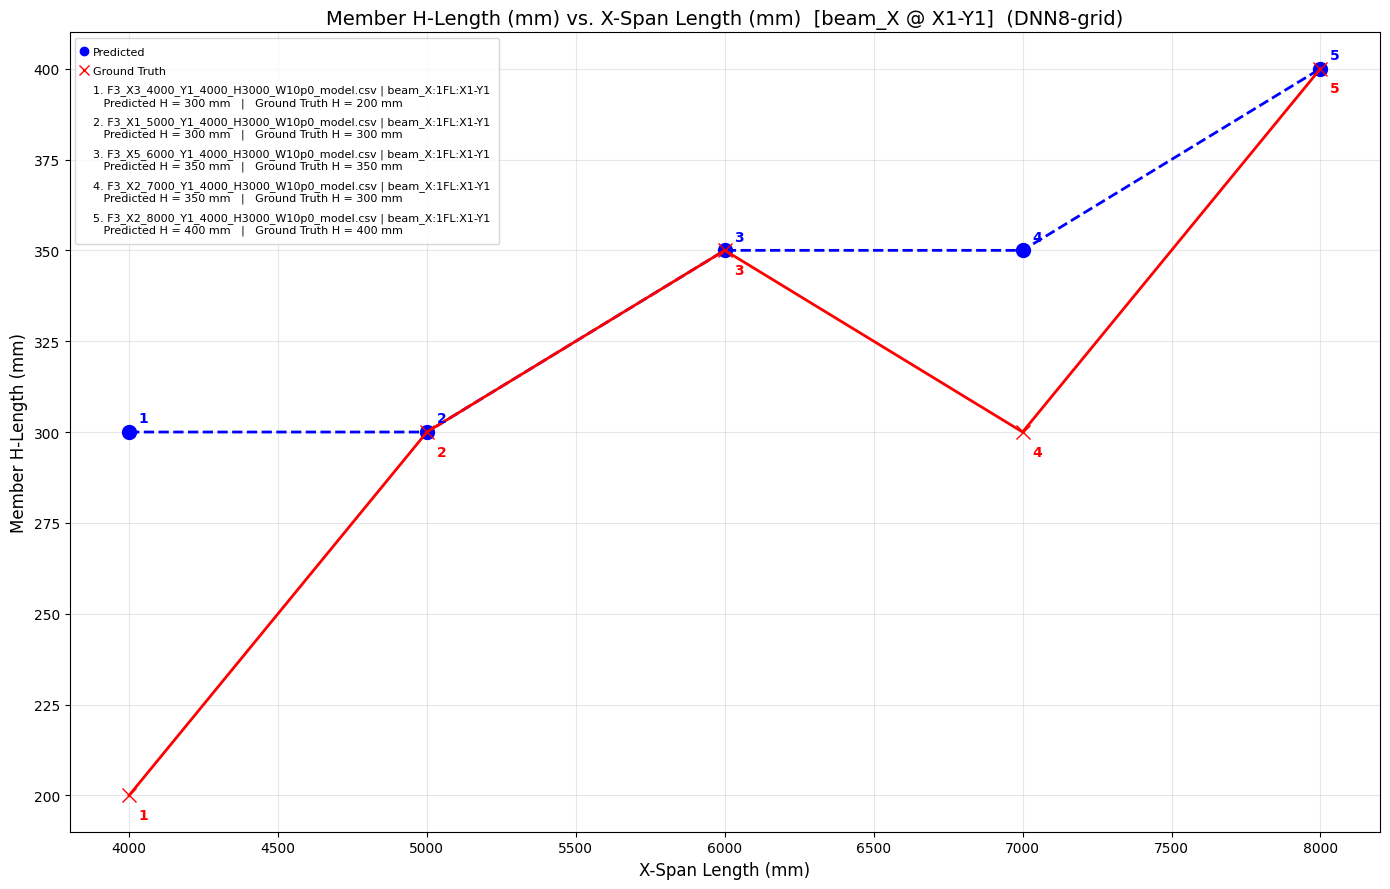

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
# Beam H vs X-span  (X-direction beam in the first bay of the first Y line)
summary_1 = plot_dim_vs_variable(df, member='beam_X', dim='H', vary='x_span', position='X1-Y1')

### Beam H vs. building load

Saved graph to: /content/drive/MyDrive/research/dnn8/dnn-results/DNN8-grid-beam_X-H-vs-Building_Load-X1-Y1.png
Building condition key: F3_X6_7000_Y1_4000_H3000_WLOAD_model.csv | beam_X:1FL:X1-Y1
Distinct values plotted (load): [6.0, 8.0, 10.0]
[1] F3_X6_7000_Y1_4000_H3000_W6p0_model.csv | beam_X:1FL:X1-Y1 : pred H=300  true H=300
[2] F3_X6_7000_Y1_4000_H3000_W8p0_model.csv | beam_X:1FL:X1-Y1 : pred H=350  true H=350
[3] F3_X6_7000_Y1_4000_H3000_W10p0_model.csv | beam_X:1FL:X1-Y1 : pred H=400  true H=350


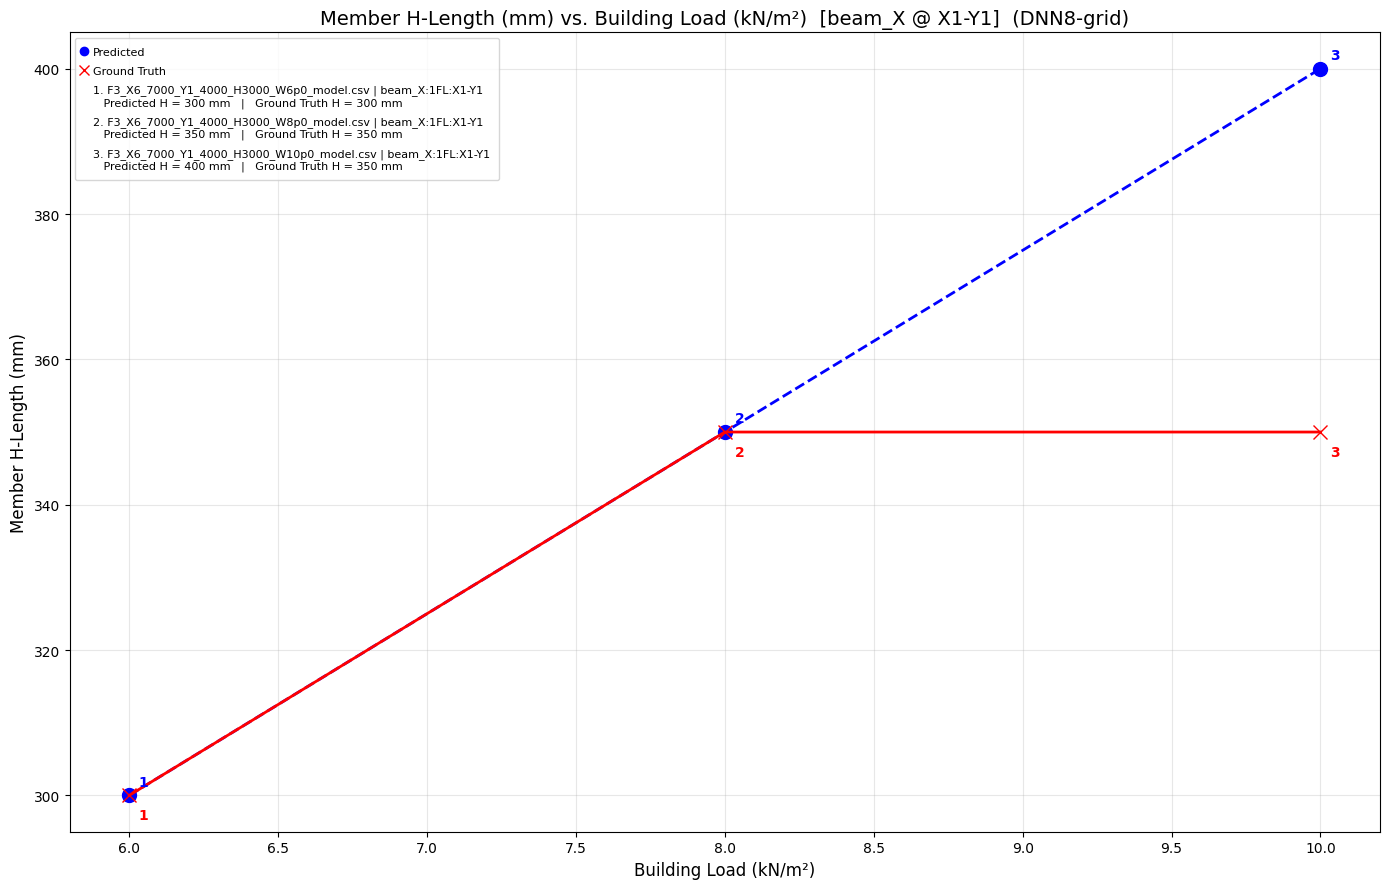

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
# Beam H vs load
summary_2 = plot_dim_vs_variable(df, member='beam_X', dim='H', vary='load', position='X1-Y1')

### Column D vs. building load

Saved graph to: /content/drive/MyDrive/research/dnn8/dnn-results/DNN8-grid-column-D-vs-Building_Load-X1-Y1.png
Building condition key: F3_X6_7000_Y1_4000_H3000_WLOAD_model.csv | column:1FL:X1-Y1
Distinct values plotted (load): [6.0, 8.0, 10.0]
[1] F3_X6_7000_Y1_4000_H3000_W6p0_model.csv | column:1FL:X1-Y1 : pred D=300  true D=300
[2] F3_X6_7000_Y1_4000_H3000_W8p0_model.csv | column:1FL:X1-Y1 : pred D=300  true D=300
[3] F3_X6_7000_Y1_4000_H3000_W10p0_model.csv | column:1FL:X1-Y1 : pred D=350  true D=350


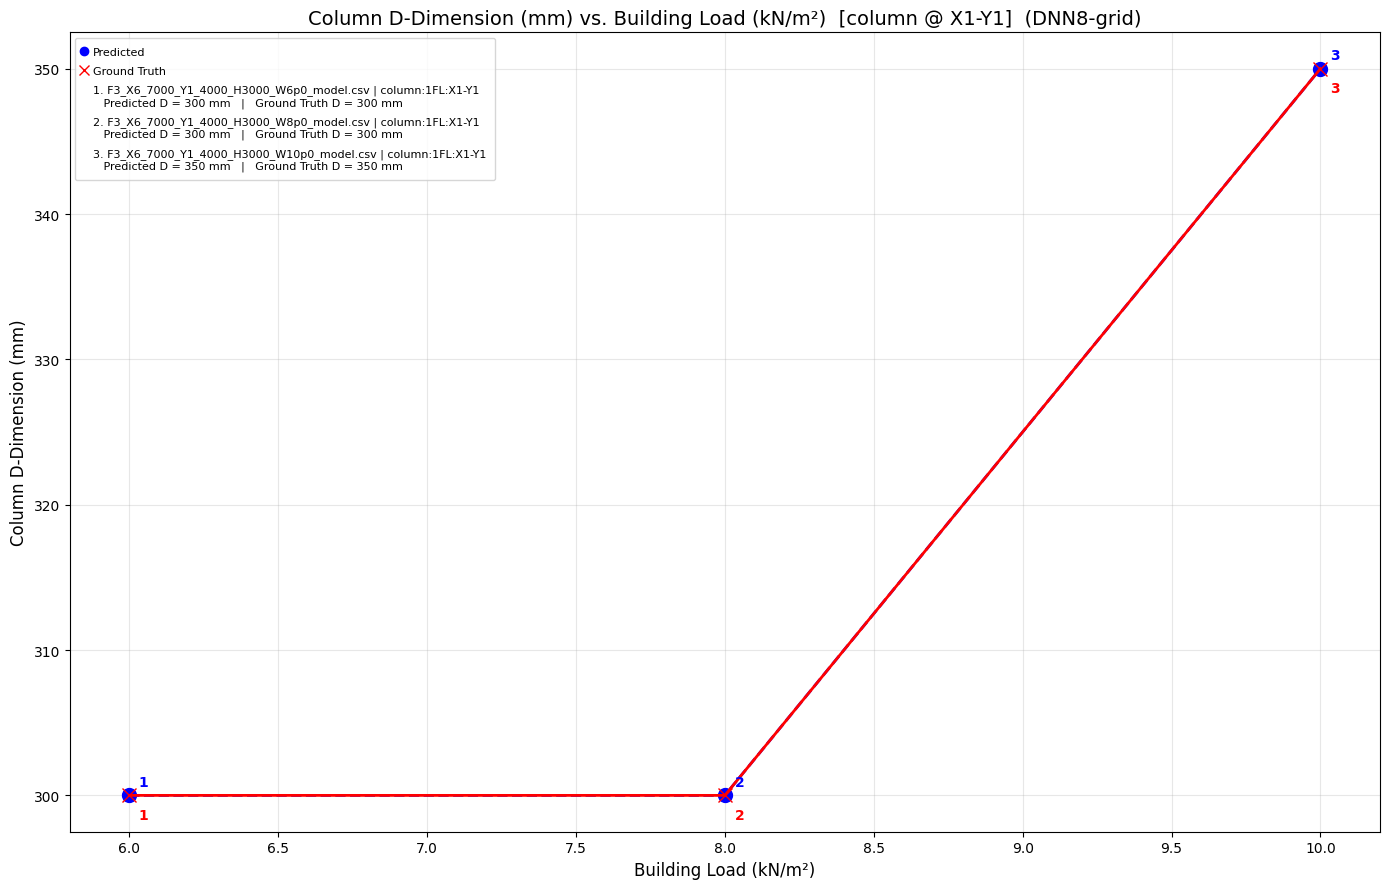

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
# Column D vs load  (corner column)
summary_3 = plot_dim_vs_variable(df, member='column', dim='D', vary='load', position='X1-Y1')

### Column D vs. floor

Saved graph to: /content/drive/MyDrive/research/dnn8/dnn-results/DNN8-grid-column-D-vs-Floor-X1-Y1.png
Building condition key: F3_X1_4000_Y1_4000_H3500_W6p0_model.csv | column:FL:X1-Y1
Distinct values plotted (story): [1, 2, 3]
[1] F3_X1_4000_Y1_4000_H3500_W6p0_model.csv | column:1FL:X1-Y1 : pred D=175  true D=200
[2] F3_X1_4000_Y1_4000_H3500_W6p0_model.csv | column:2FL:X1-Y1 : pred D=200  true D=175
[3] F3_X1_4000_Y1_4000_H3500_W6p0_model.csv | column:3FL:X1-Y1 : pred D=150  true D=150


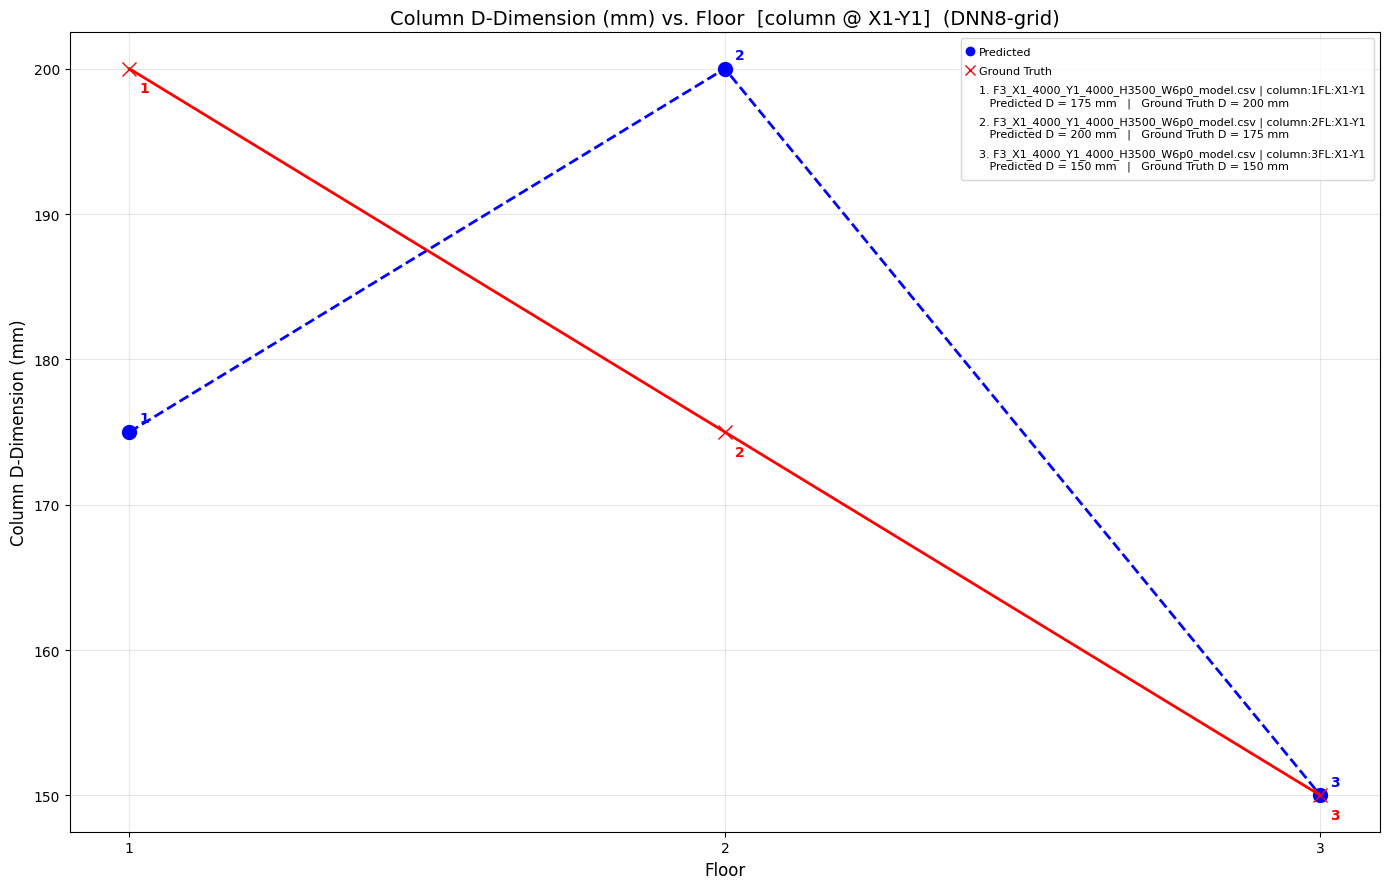

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
# Column D vs floor (corner column, all floors of one building)
summary_4 = plot_dim_vs_variable(df, member='column', dim='D', vary='story', position='X1-Y1')

### Beam H vs. floor height

Saved graph to: /content/drive/MyDrive/research/dnn8/dnn-results/DNN8-grid-beam_X-H-vs-Floor_Height-X1-Y1.png
Building condition key: F3_X1_7000_Y1_4000_HFLOOR_W9p0_model.csv | beam_X:1FL:X1-Y1
Distinct values plotted (floor_height): [4000, 4500, 5000]
[1] F3_X1_7000_Y1_4000_H4000_W9p0_model.csv | beam_X:1FL:X1-Y1 : pred H=400  true H=400
[2] F3_X1_7000_Y1_4000_H4500_W9p0_model.csv | beam_X:1FL:X1-Y1 : pred H=400  true H=500
[3] F3_X1_7000_Y1_4000_H5000_W9p0_model.csv | beam_X:1FL:X1-Y1 : pred H=400  true H=400


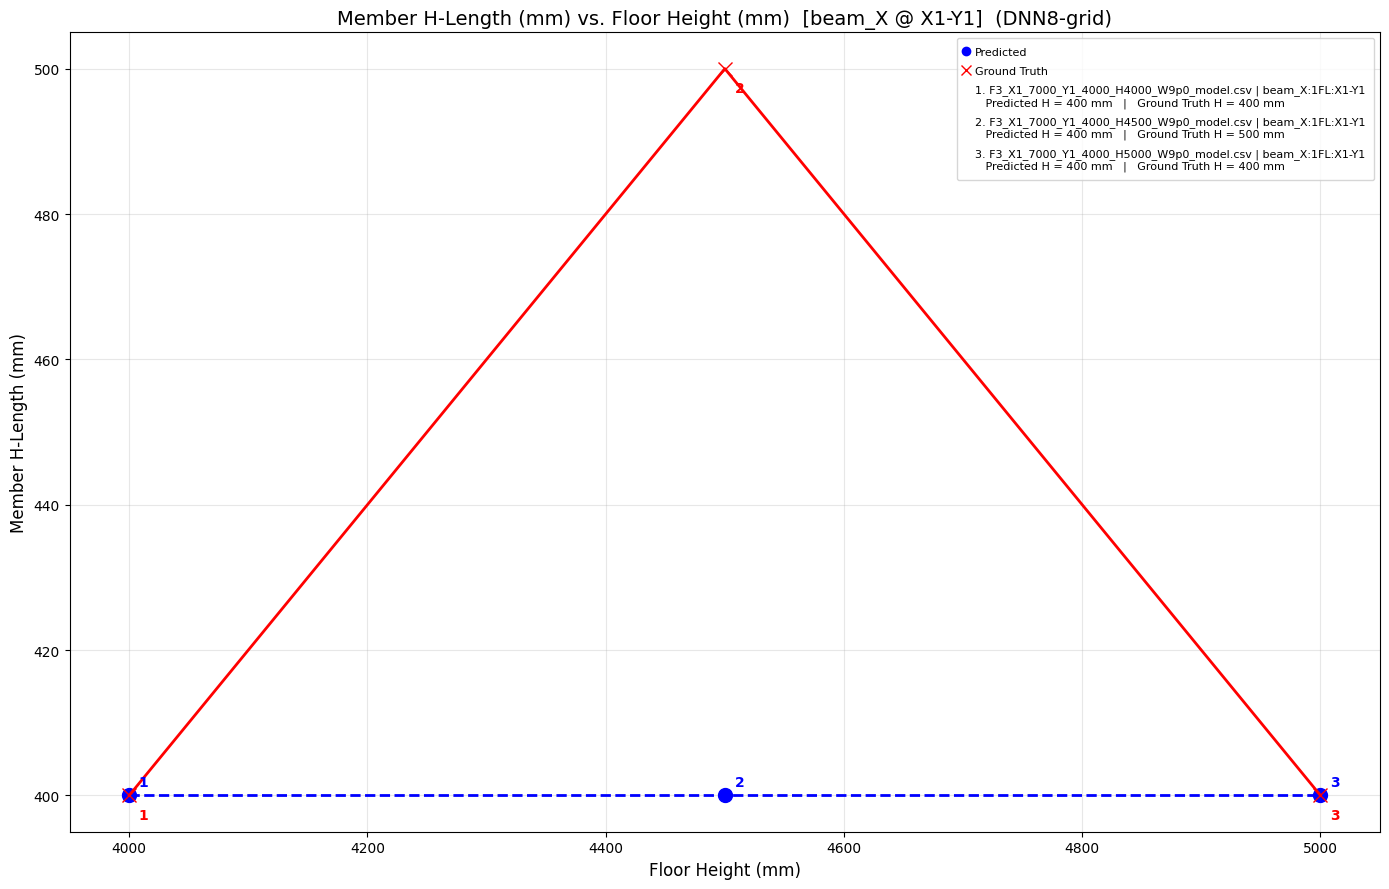

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# Beam H vs floor height
summary_5 = plot_dim_vs_variable(df, member='beam_X', dim='H', vary='floor_height', position='X1-Y1')

### Column D vs. floor height

Saved graph to: /content/drive/MyDrive/research/dnn8/dnn-results/DNN8-grid-column-D-vs-Floor_Height-X1-Y1.png
Building condition key: F3_X1_7000_Y1_4000_HFLOOR_W9p0_model.csv | column:1FL:X1-Y1
Distinct values plotted (floor_height): [4000, 4500, 5000]
[1] F3_X1_7000_Y1_4000_H4000_W9p0_model.csv | column:1FL:X1-Y1 : pred D=250  true D=250
[2] F3_X1_7000_Y1_4000_H4500_W9p0_model.csv | column:1FL:X1-Y1 : pred D=300  true D=300
[3] F3_X1_7000_Y1_4000_H5000_W9p0_model.csv | column:1FL:X1-Y1 : pred D=300  true D=300


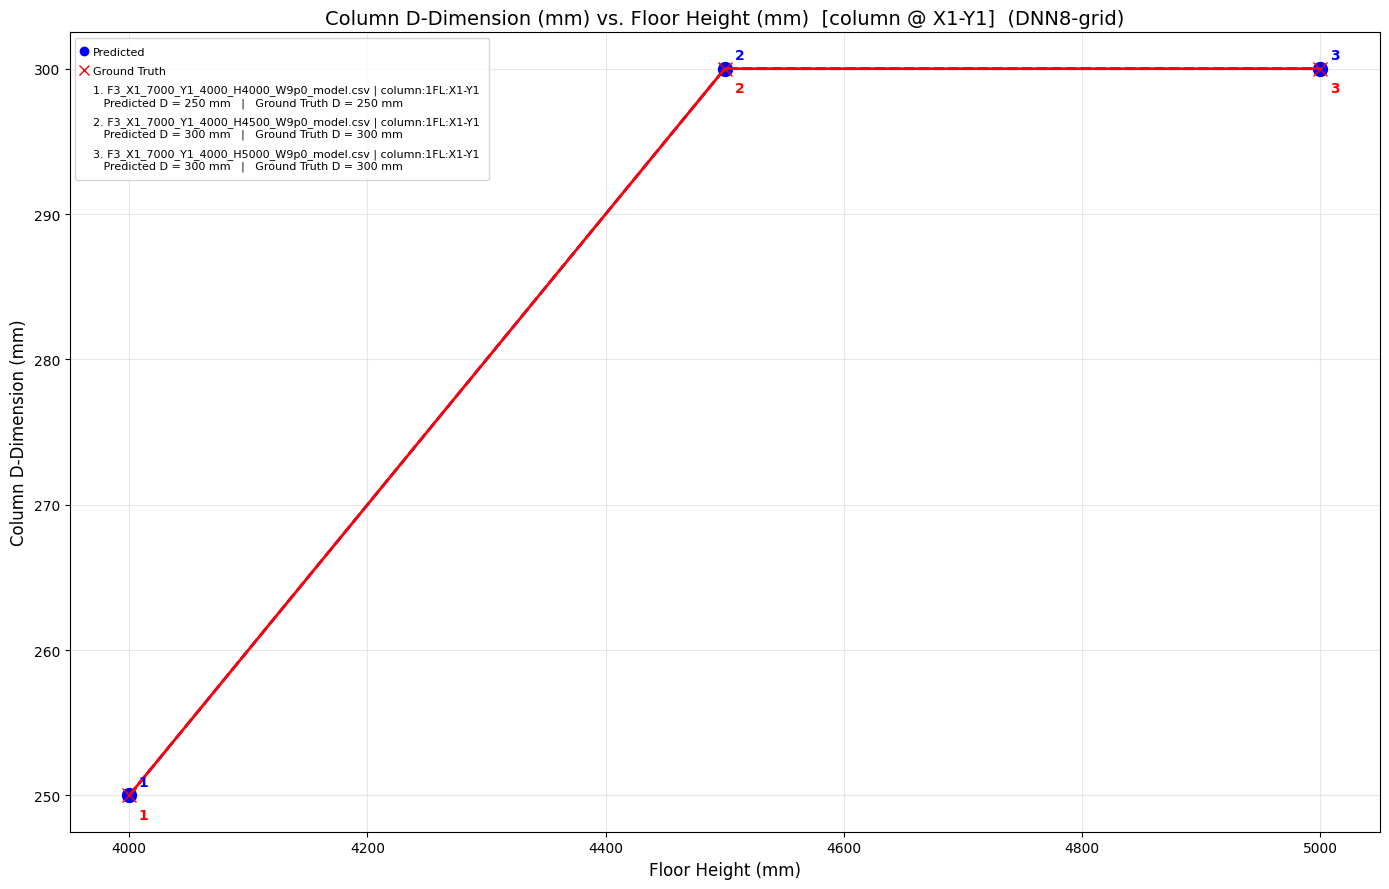

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# Column D vs floor height
summary_6 = plot_dim_vs_variable(df, member='column', dim='D', vary='floor_height', position='X1-Y1')